In [2]:
#Inicializacion
#importar librerias utilizadas so far 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import scipy.stats as st




In [4]:
#Abrir el archivo 

from pathlib import Path
candidates = [Path('data') / 'games.csv', Path('Proyecto integrado') / 'data' / 'games.csv']
for p in candidates:
    if p.exists():
        juegos = pd.read_csv(p)
        break
else:
    raise FileNotFoundError(f'No se encontró games.csv en {candidates}')



FileNotFoundError: [Errno 2] No such file or directory: 'Proyecto integrado/data/games.csv'

In [3]:
#informacion General del archivo 
juegos.info()
print('-------------Primeras 5 filas del archivo---------------------')#Primeras 5 filas del archivo 
print(juegos.head())
print(' Muestra de como de ven los arvhicos')
juegos.sample(5, random_state=42) #random_state para que sea reproducible
print('---------------Describir el archivo-------------------')#Describir el archivo
print(juegos.describe())
print('----------------Verificar valores nulos------------------')#Verificar si hay valores nulos
print(juegos.isnull().sum())
print('-------------verificar duplicados---------------------')#Verificar si hay duplicados
print(juegos.duplicated().sum())
print('----------------------------------')#Verificar el tipo de datos de cada columna


print('Separador  ')


print('ESto es una prueba de como se ven los datos')
print(juegos.head(10)) #ver las primeras 10 filas del archivo



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB
-------------Primeras 5 filas del archivo---------------------
                       Name Platform  Year_of_Release         Genre  NA_sales  \
0                Wii Sports      Wii           2006.0        Sports     41.36   
1         Super 

In [4]:
#Revisar columnas
print(juegos.columns)

#correccion de nombres de columnas
juegos.columns = juegos.columns.str.strip().str.lower().str.replace(' ', '_', regex=False)

#Revisar columnas nuevamente
print(juegos.columns)



Index(['Name', 'Platform', 'Year_of_Release', 'Genre', 'NA_sales', 'EU_sales',
       'JP_sales', 'Other_sales', 'Critic_Score', 'User_Score', 'Rating'],
      dtype='object')
Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')


In [5]:
#convertir datos a los tipos correctos,  year_of_release por si se tiene que operar con ello
juegos['year_of_release'] = pd.to_numeric(juegos['year_of_release'], errors='coerce')
print(juegos['year_of_release'].dtype) 
#convertir user_score a numerico, ya que puede tener valores no numericos
print(juegos['rating'].unique())#verificar los valores unicos de la columna rating
juegos['user_score'] = pd.to_numeric(juegos['user_score'], errors='coerce') #convertira numerico, si no se puede convertir a numero, se pondra NaN
print(juegos['user_score'].dtype) #verificar el tipo de dato de la columna user_score





float64
['E' nan 'M' 'T' 'E10+' 'K-A' 'AO' 'EC' 'RP']
float64


In [6]:
#revisamos como se ven los datos nulos en cada columna 
print('-----------------Valores nulos en la columna name------------------')
print(juegos[juegos['name'].isna()])
print('-----------------valores nulos de la coluna year_of_release------------------')
print(juegos[juegos['year_of_release'].isna()])
print('-----------------valores nulos de la coluna genre------------------')
print(juegos[juegos['genre'].isna()])
print('-----------------valores nulos de la columna critic_score------------------')
print(juegos[juegos['user_score'].isna()].sample(5))
print('-----------------valores nulos de la columna user_score------------------')
print(juegos[juegos['user_score'].isna()].sample(5))
print('-----------------valores nulos de la columna rating------------------')
print(juegos[juegos['rating'].isna()].sample(5))
print(juegos['rating'].isna().sum()) #verificar cuantos nulos hay en la columna rating

#Aqui describiremos los datos para decidir que hacer con los nulos
print('-----------------Describir el archivo-------------------')#Describir el archivo
print(juegos.describe())	




-----------------Valores nulos en la columna name------------------
      name platform  year_of_release genre  na_sales  eu_sales  jp_sales  \
659    NaN      GEN           1993.0   NaN      1.78      0.53      0.00   
14244  NaN      GEN           1993.0   NaN      0.00      0.00      0.03   

       other_sales  critic_score  user_score rating  
659           0.08           NaN         NaN    NaN  
14244         0.00           NaN         NaN    NaN  
-----------------valores nulos de la coluna year_of_release------------------
                                    name platform  year_of_release  \
183                      Madden NFL 2004      PS2              NaN   
377                     FIFA Soccer 2004      PS2              NaN   
456           LEGO Batman: The Videogame      Wii              NaN   
475           wwe Smackdown vs. Raw 2006      PS2              NaN   
609                       Space Invaders     2600              NaN   
...                                  ...   

Una vez revisados se determinan los siguients cambios : en la columna year of release se eliminan ya que solo es 1.64 % dela data completa,en la columna ['name'] se eliminan ya que son solo 2 rows, en la columna 'genre' se eliminan tambien ya que son solo 2, en la columna 'critic_score' se usara la media, ya que la desviacion estandar es unicamente del 13.98, la media esta en 68.96, ya que es el 48% de la data, de igual manera con la columna 'user_score' se hara de igual manera, media  7.12, desviacion estandar 1.5.

In [7]:
# Eliminar filas con valores nulos en columnas clave
juegos.dropna(subset=['name', 'year_of_release', 'genre'], inplace=True)

# Rellenar critic_score con la media
juegos['critic_score'] = juegos['critic_score'].fillna(juegos['critic_score'].mean())

# Rellenar user_score con la media
juegos['user_score'] = juegos['user_score'].fillna(juegos['user_score'].mean())

# Verificar que los ratings no son anteriores a 1994
print(juegos[juegos['rating'].notna()]['year_of_release'].ge(1994).all())

# Rellenar rating con 'Unknown'
juegos['rating'] = juegos['rating'].fillna('Unknown')

# Verificar si hay valores nulos después de la limpieza
print('-----------------Valores nulos después de la limpieza------------------')
print(juegos.isna().sum())



False
-----------------Valores nulos después de la limpieza------------------
name               0
platform           0
year_of_release    0
genre              0
na_sales           0
eu_sales           0
jp_sales           0
other_sales        0
critic_score       0
user_score         0
rating             0
dtype: int64


In [8]:
juegos['total_sale'] = juegos[['na_sales', 'eu_sales', 'jp_sales', 'other_sales']].sum(axis=1) # creamos. una columna con el total de ventas



In [9]:
#vemos cuantos juegos se lanzaron por año
juegos_por_año = juegos.groupby('year_of_release')['name'].count()


Despues de revisar como se ven los datos al tratar de agrupar, se creara una seleccion por peridos, 1980 - 1992 - Clasics, 1993 - 2004 Golden Hits, 2005- 2016 contemporaneos 

In [10]:
#creamos una selecciones para agrupar los juegos por periodo de tiempo
condiciones = [ 
	juegos['year_of_release'] <= 1992,
	juegos['year_of_release'].between(1993, 2004),
	juegos['year_of_release']>= 2005]
selecciones = ['1980 - 1992', '1993 - 2004', '2005 - 2016']
juegos['periodo'] = np.select(condiciones, selecciones, default='Desconocido') #creamos una nueva columna con los periodos de tiempo

# Agrupamos los juegos por periodo de tiempo y genero
juegos_por_periodo_genero = juegos.groupby(['periodo'])['name'].count().reset_index()
print(juegos_por_periodo_genero)

       periodo   name
0  1980 - 1992    305
1  1993 - 2004   4867
2  2005 - 2016  11272


En este caso no consideramos que el periodo sea relevante, ya que no hay suficientes datos para hacer una comparativa significativa entre periodos. Sin embargo, es importante tener en cuenta que la falta de datos puede limitar nuestras conclusiones y recomendaciones.

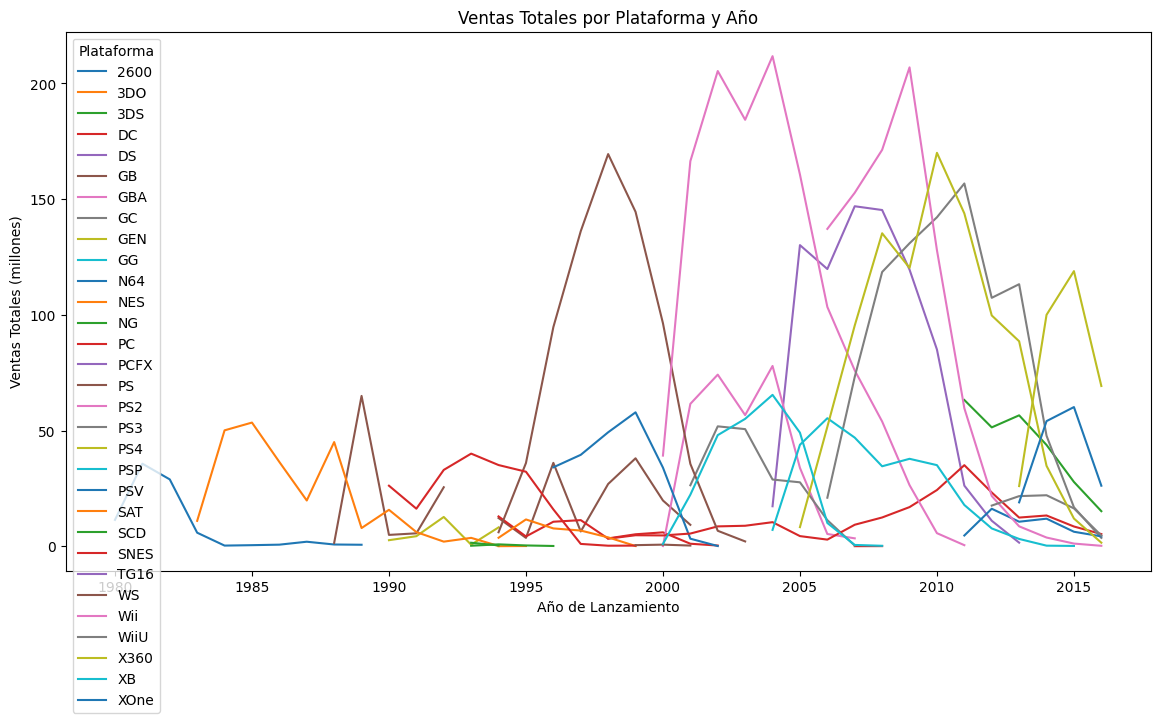

In [11]:
#graficamos las ventas totales de cada plataforma por año
ventas_agrupadas = juegos.groupby(['year_of_release', 'platform'])['total_sale'].sum().unstack()
ventas_agrupadas.plot(kind='line', figsize=(14,7))
plt.title('Ventas Totales por Plataforma y Año')
plt.xlabel('Año de Lanzamiento')
plt.ylabel('Ventas Totales (millones)')
plt.legend(title='Plataforma')


Debido a la cantidad de datos se crea mucho ruido en el grafico, vamos a graficar unicamente las 10 consolas con mas ventas

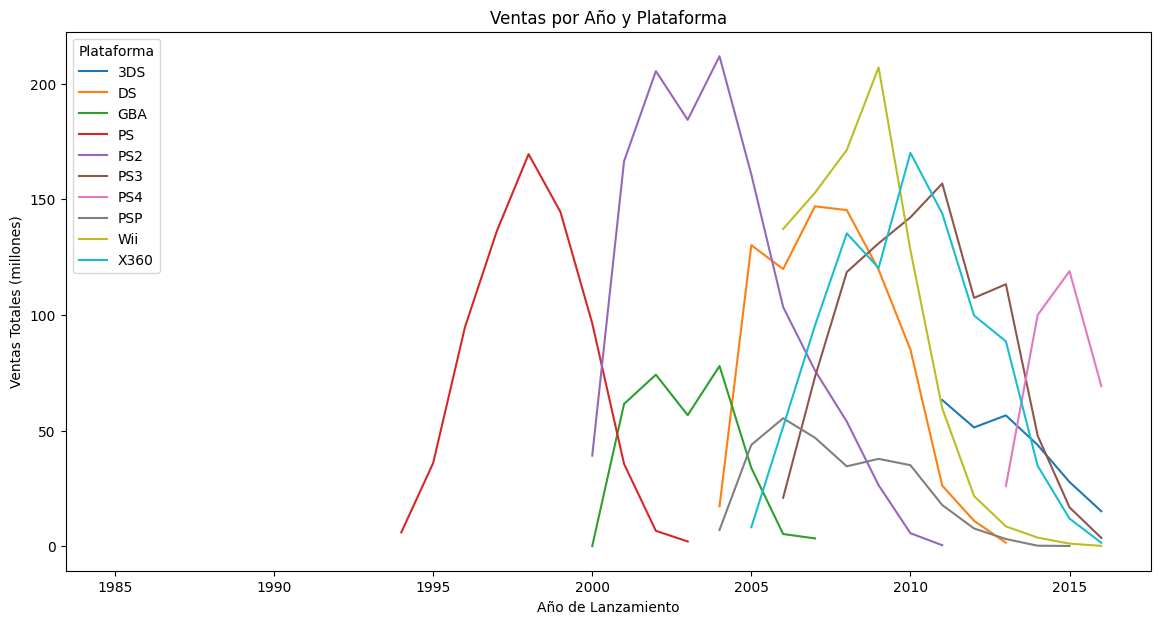

In [12]:
top_10 = juegos.groupby('platform')['total_sale'].sum().sort_values(ascending=False).head(10).index 
consolas_top= juegos[juegos['platform'].isin(top_10)]

ventas_por_año_plataform = consolas_top.groupby(['year_of_release','platform'])['total_sale'].sum().unstack()
ventas_por_año_plataform.plot(kind='line', figsize=(14,7))
plt.title('Ventas por Año y Plataforma')
plt.xlabel('Año de Lanzamiento')
plt.ylabel('Ventas Totales (millones)')
plt.legend(title='Plataforma')


Tras analizar la distribución de lanzamientos y la evolución de las ventas por consola, se ha determinado que los datos más consistentes y representativos comienzan a partir del año 2005.
Este período incluye la mayoría de las consolas activas en la generación previa a 2017, con volúmenes suficientes para construir un modelo confiable. Por lo tanto, para fines de análisis y modelado, se trabajará con los datos desde 2005 hasta 2016, excluyendo 2017 para simular una predicción futura basada únicamente en información histórica.
A continuación, se seleccionan los datos de este período, ya que antes de 2005 Sony lideraba completamente el mercado sin una competencia equilibrada, lo que podría sesgar el análisis.

In [13]:
consolas_top_2005= consolas_top[(consolas_top['year_of_release']>= 2005) & (consolas_top['year_of_release'] < 2017)]

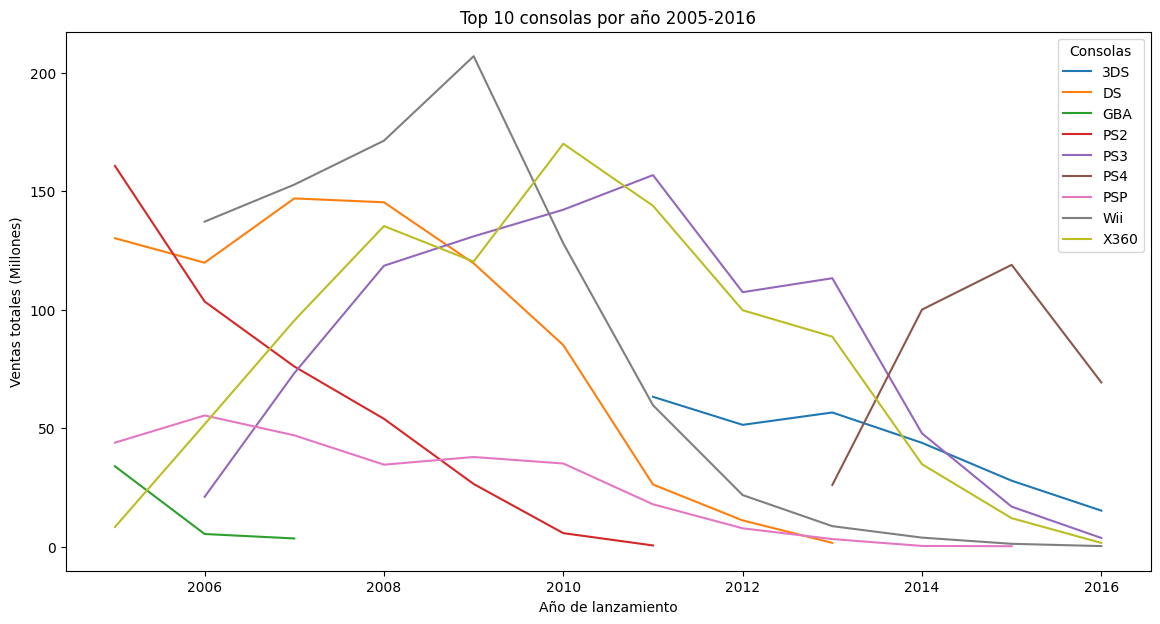

In [14]:
grafico_top_2005 = consolas_top_2005.groupby(['year_of_release','platform'])['total_sale'].sum().unstack()
grafico_top_2005.plot(kind='line', figsize=(14,7))
plt.title('Top 10 consolas por año 2005-2016')
plt.xlabel('Año de lanzamiento')
plt.ylabel('Ventas totales (Millones)')
plt.legend(title='Consolas')
plt.show()


Con esta información y el periodo definido (2005–2016), se establece una base sólida para crear un modelo predictivo orientado al año 2017.
En el gráfico se observa que la PS2 se encontraba en sus últimos años de vida útil, mientras que las consolas de nueva generación comenzaban a liderar las ventas del mercado de sobremesa. La Wii mostró un fuerte liderazgo en sus primeros años, pero también una caída abrupta posteriormente. En contraste, la PS3 y la Xbox 360 mantuvieron un crecimiento más sostenido y ventas consistentes a lo largo del tiempo.
En cuanto a plataformas portátiles, la Nintendo DS dominó claramente este segmento, con una larga vida desde 2004 hasta 2013. La Game Boy Advance, por otro lado, ya estaba prácticamente fuera del mercado en este período. La PSP aparece representada en el gráfico, aunque no logró competir en volumen de ventas con la DS.
Hasta este punto, la PS4 es la única consola de la siguiente generación que comienza a posicionarse con fuerza en el mercado y, dado su crecimiento, se considera una plataforma con potencial para el año 2017.

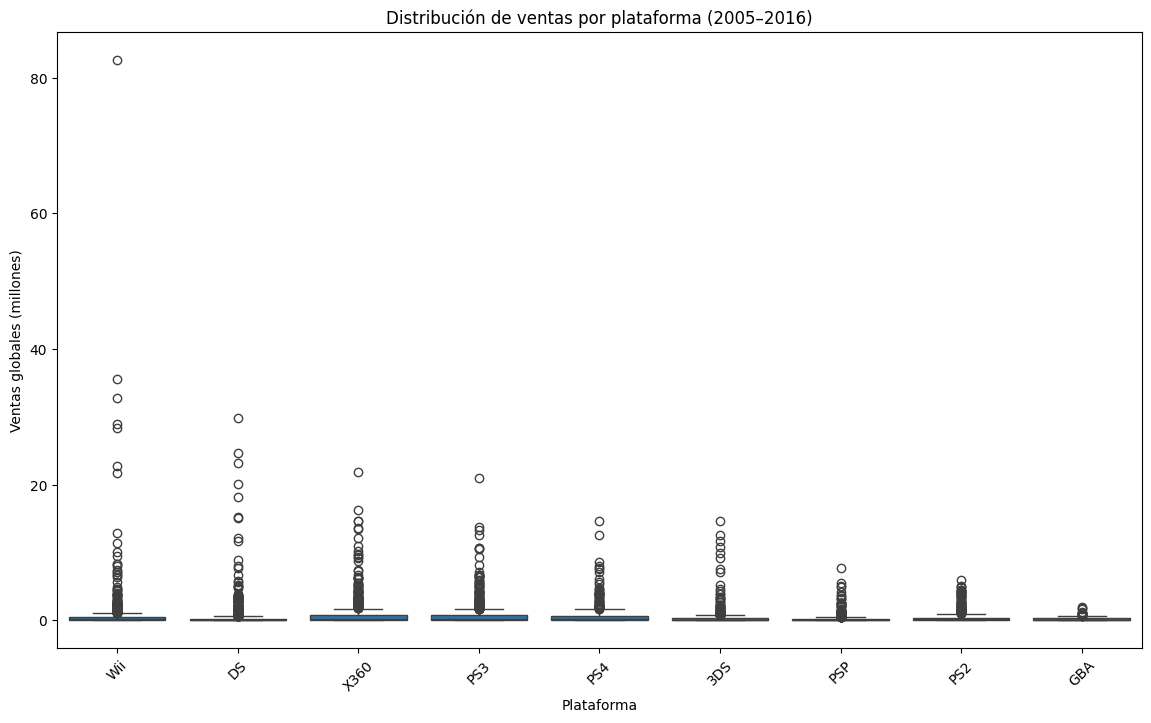

In [15]:
plt.figure(figsize=(14, 8))
sns.boxplot(x='platform', y='total_sale', data=consolas_top_2005)
plt.title('Distribución de ventas por plataforma (2005–2016)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas globales (millones)')
plt.xticks(rotation=45)
plt.show()

DEbido a la dificultad para leer el grafico, se revisan esos valores atipicos de la consola wii se revisan y se extran para hacer el analisis del grafico ya que la mayoria de datos, se encuentra cerca ente 0 y 2 millones.

                         name  total_sale
0                  Wii Sports       82.54
2              Mario Kart Wii       35.52
3           Wii Sports Resort       32.77
7                    Wii Play       28.91
8   New Super Mario Bros. Wii       28.32
13                    Wii Fit       22.70
15               Wii Fit Plus       21.80
39    Super Smash Bros. Brawl       12.84
49         Super Mario Galaxy       11.35
61               Just Dance 3       10.12


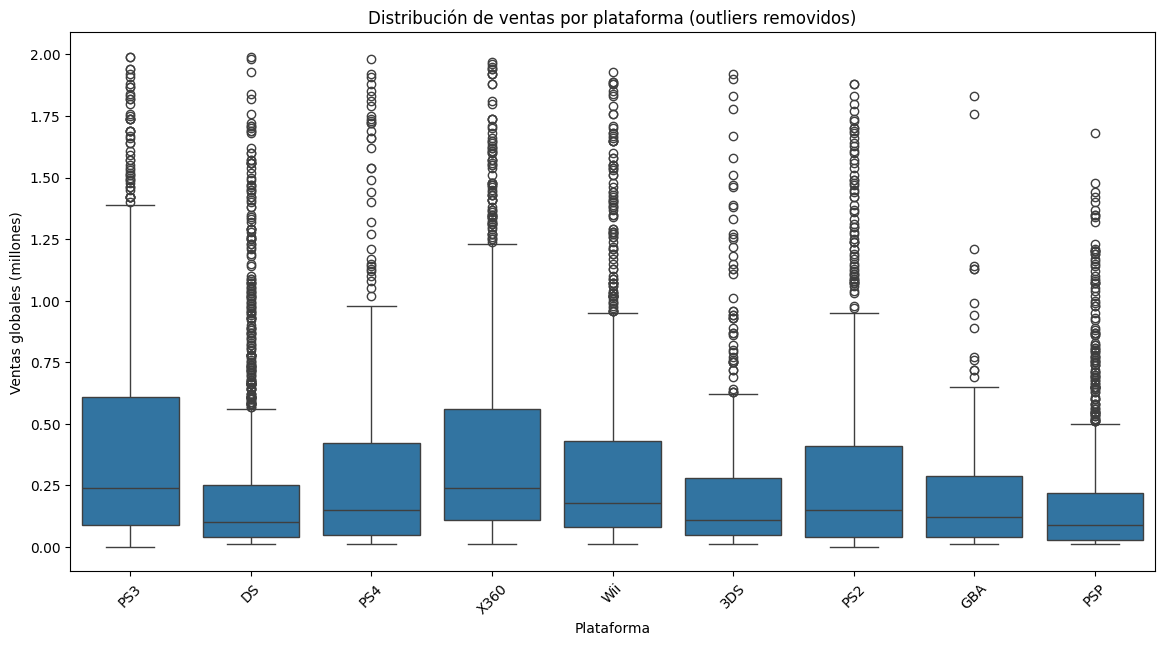

In [16]:
#Se revisa ese outlier cercano a los 80 millones en la wii
wii_games = consolas_top_2005[consolas_top_2005['platform'] == 'Wii']
print(wii_games[['name', 'total_sale']].sort_values('total_sale', ascending=False).head(10))



ventas_sin_outliers = consolas_top_2005[consolas_top_2005['total_sale'] < 2]

plt.figure(figsize=(14, 7))
sns.boxplot(x='platform', y='total_sale', data=ventas_sin_outliers)
plt.title('Distribución de ventas por plataforma (outliers removidos)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas globales (millones)')
plt.xticks(rotation=45)
plt.show()


In [17]:
ventas_promedio = consolas_top_2005.groupby('platform')['total_sale'].mean()
print(ventas_promedio)

platform
3DS     0.503535
DS      0.374578
GBA     0.236333
PS2     0.400432
PS3     0.713124
PS4     0.801378
PSP     0.239788
Wii     0.692986
X360    0.780227
Name: total_sale, dtype: float64


Como se puede observar en el gráfico, la mayoría de las consolas presentan una mediana de ventas por debajo de 0.25 millones de unidades, es decir, menos de 250,000 copias por juego.
Esto refuerza que la mediana es una medida más confiable que la media, ya que la media se ve distorsionada por los outliers —juegos con ventas extremadamente altas.

Un caso interesante es la Nintendo DS, una de las consolas más exitosas en términos de volumen total de ventas.
Sin embargo, el gráfico revela que alrededor del 75% de sus títulos vendieron menos de 250,000 unidades, lo que sugiere que, aunque tuvo un catálogo amplio, la mayoría de los juegos no alcanzaron cifras significativas.

En contraste, consolas como PS3, Xbox 360 e incluso la PS2 en sus últimos años muestran una distribución de ventas más consistente y estable, con mejores resultados promedio por título.

A continuacion se hace un analisis exploratoria sobre la correlacion entre el total de ventas y la critica del publico y las criticas de los profesionales.

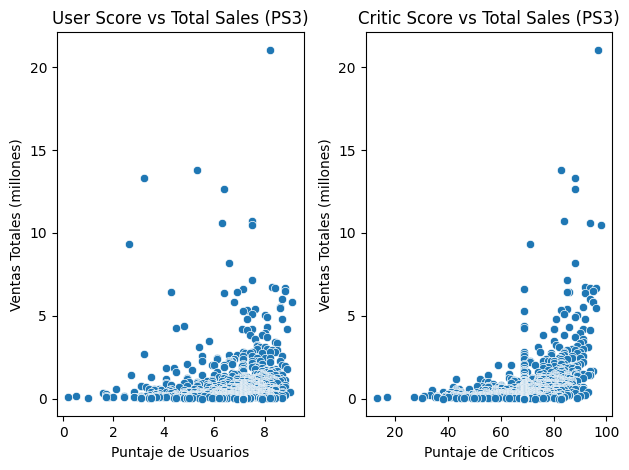

Correlación User Score - Total Sales: 0.07992943847782746
Correlación Critic Score - Total Sales: 0.41940545215076935


In [18]:
ps3 = juegos[(juegos['platform'] == 'PS3') &
             (juegos['user_score'].notna()) &
             (juegos['critic_score'].notna()) &
             (juegos['total_sale'].notna())] #Filtrar solo los huegos de ps3 con la informacion que necsitamos, excluyendo na, aunque ya anteiormente se han eliminado

# Gráfico 1: User Score vs Total Sales
plt.subplot(1, 2, 1)
sns.scatterplot(data=ps3, x='user_score', y='total_sale')
plt.title('User Score vs Total Sales (PS3)')
plt.xlabel('Puntaje de Usuarios')
plt.ylabel('Ventas Totales (millones)')

# Gráfico 2: Critic Score vs Total Sales
plt.subplot(1, 2, 2)
sns.scatterplot(data=ps3, x='critic_score', y='total_sale')
plt.title('Critic Score vs Total Sales (PS3)')
plt.xlabel('Puntaje de Críticos')
plt.ylabel('Ventas Totales (millones)')

plt.tight_layout()
plt.show()

ps3[['user_score', 'critic_score', 'total_sale']].describe()

print('Correlación User Score - Total Sales:', ps3['user_score'].corr(ps3['total_sale']))
print('Correlación Critic Score - Total Sales:', ps3['critic_score'].corr(ps3['total_sale']))




Aunque los datos muestran una correlación de 0.799 entre las reseñas de usuarios (user_score) y las ventas totales, el gráfico revela que existen varios juegos con puntajes bajos por parte de los usuarios pero con ventas muy altas, lo que indica que esta relación no es del todo lineal ni directa.
En contraste, la correlación con critic_score es de 0.419, pero el gráfico muestra que los juegos con malas críticas rara vez alcanzan altas ventas, lo cual sugiere que, aunque la correlación sea más baja numéricamente, la relación es más consistente visualmente.
Esto puede indicar que, al menos para la PS3, las reseñas de críticos son un mejor predictor visual de ventas que las de usuarios, aunque la correlación estadística sea menor.

<function matplotlib.pyplot.show(close=None, block=None)>

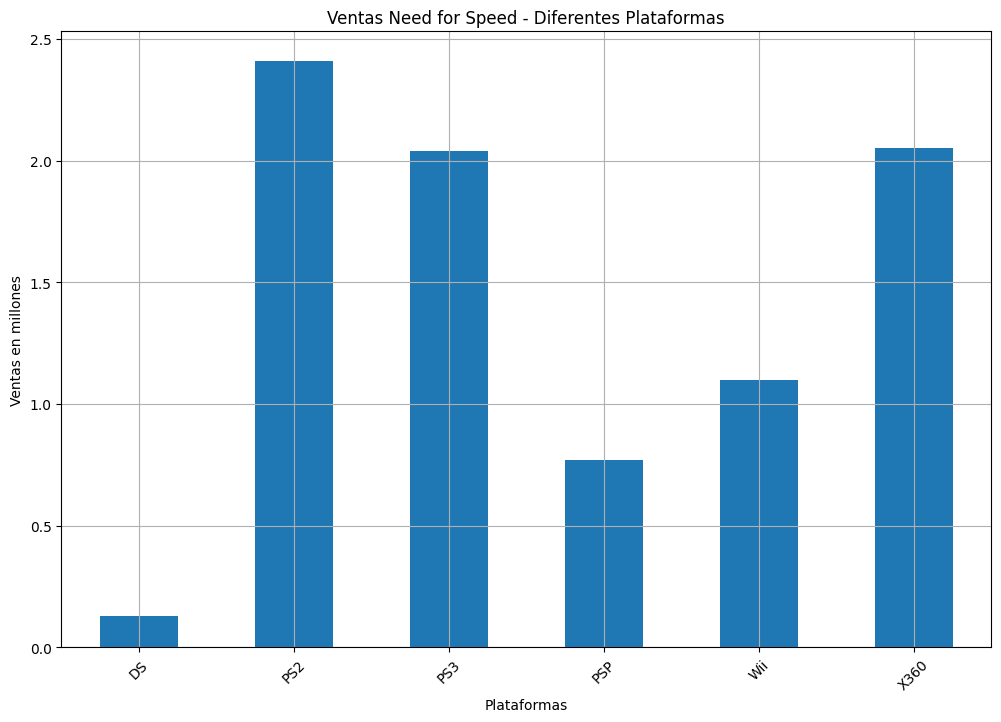

In [19]:
# Filtrar juegos que están en más de una plataforma
multiplataforma_top = consolas_top[consolas_top.duplicated('name', keep=False)]

# Ver cuántas plataformas tiene cada juego
multiplataforma_top.groupby('name')['platform'].nunique().sort_values(ascending=False).head(10)

#comparar ventas de un mismo videojuego en diferentes plataformas 
nfs= multiplataforma_top[(multiplataforma_top['name']== 'Need for Speed: ProStreet')]
nfs_grouped= nfs.groupby('platform')['total_sale'].sum()
nfs_grouped.plot(kind='bar', figsize=(12,8), title='Ventas Need for Speed - Diferentes Plataformas')
plt.ylabel('Ventas en millones')
plt.xlabel('Plataformas')
plt.xticks(rotation=45)
plt.grid(True)
plt.show 



En este gráfico podemos observar que Need for Speed: ProStreet tuvo un desempeño notablemente superior en consolas de sobremesa en comparación con plataformas portátiles.
Para entender más a fondo estas diferencias, sería útil analizar variables como la clasificación ESRB o el perfil demográfico del jugador por consola.

A continuacion se hace un grafico exploratorio para observar las ventas por genero de todas las consolas.

<function matplotlib.pyplot.show(close=None, block=None)>

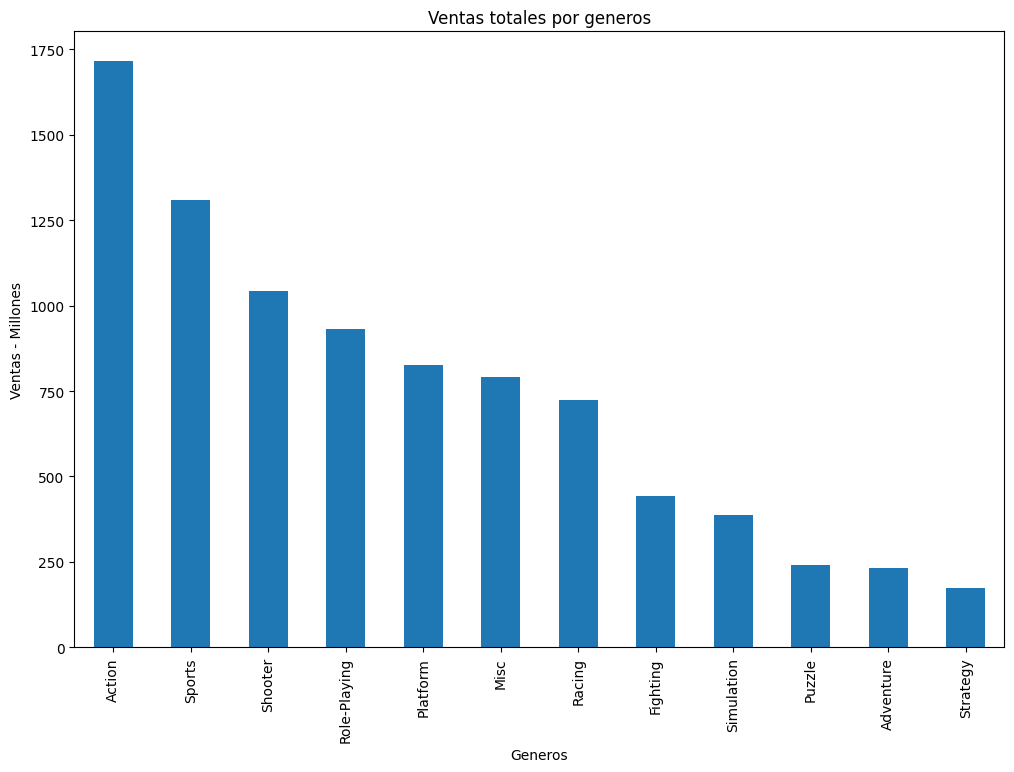

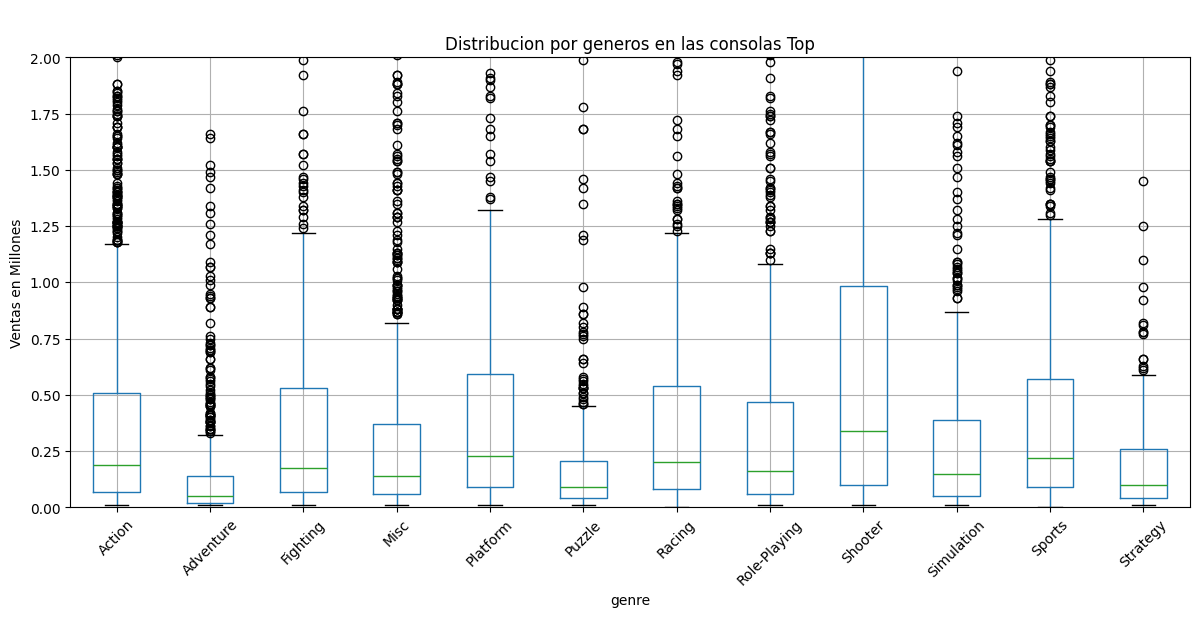

In [20]:
ventas_por_genero= juegos.groupby('genre')['total_sale'].sum().sort_values(ascending=False)
ventas_por_genero.plot(kind='bar', figsize=(12,8))
plt.title('Ventas totales por generos')
plt.xlabel('Generos')
plt.ylabel('Ventas - Millones')
plt.show

consolas_top_2005.boxplot(column='total_sale', by='genre',figsize=(14,6),rot=45)
plt.ylim(0,2)
plt.title('Distribucion por generos en las consolas Top')
plt.suptitle(' ')
plt.ylabel('Ventas en Millones')
plt.show



Con estos gráficos podemos observar que, si bien el género Action lidera en ventas totales, sus resultados por título no son consistentes. Esto indica que hay algunos outliers (juegos extremadamente exitosos) que elevan la media del género.
En contraste, el género Shooter presenta una distribución más homogénea, donde la mayoría de sus títulos tienen ventas relativamente altas y concentradas, lo que sugiere un desempeño más estable.
En el caso de Sports, es importante considerar la influencia de bundles, ya que podrían inflar las cifras sin reflejar necesariamente la preferencia directa del consumidor. Para un análisis más preciso, sería útil separar esos casos del resto de los datos.

A constinuacion se muestra una clasificaion por regiones

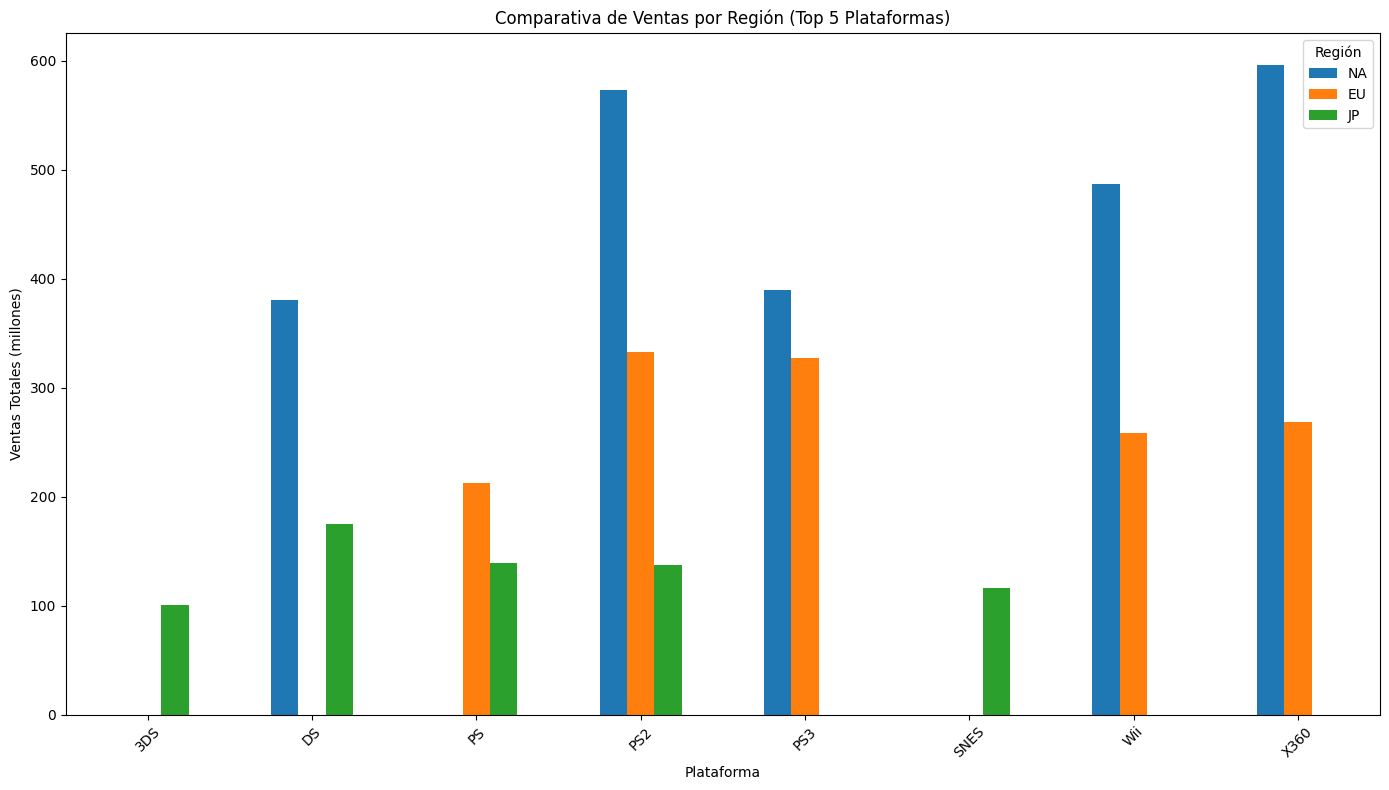

In [21]:
#perfil de usuario NA
na_sales_ordered = juegos.groupby('platform')['na_sales'].sum().sort_values(ascending=False)
na_sales_top_5= na_sales_ordered.head(5)
genres_na_sales = juegos.groupby('genre')['na_sales'].sum().sort_values(ascending=False)
genres_na_top_5= genres_na_sales.head(5)
clasifications_na = juegos.groupby('rating')['na_sales'].sum().sort_values(ascending=False)
clasifications_na_top_5= clasifications_na.head(5)

#perfil de usuario EU
eu_sales_ordered= juegos.groupby('platform')['eu_sales'].sum().sort_values(ascending=False)
eu_sales_top_5= eu_sales_ordered.head(5)
genres_eu_sales = juegos.groupby('genre')['eu_sales'].sum().sort_values(ascending=False)
genres_eu_top_5= genres_eu_sales.head(5)
clasifications_eu = juegos.groupby('rating')['eu_sales'].sum().sort_values(ascending=False)
clasifications_eu_top_5= clasifications_eu.head(5)

#Perfil de usuario JP
jp_sales_ordered= juegos.groupby('platform')['jp_sales'].sum().sort_values(ascending=False)
jp_sales_top_5= jp_sales_ordered.head(5)
genres_jp_sales = juegos.groupby('genre')['jp_sales'].sum().sort_values(ascending=False)
genres_jp_top_5= genres_jp_sales.head(5)
clasifications_jp = juegos.groupby('rating')['jp_sales'].sum().sort_values(ascending=False)
clasifications_jp_top_5= clasifications_jp.head(5)

#Grafica comparativa de ventas totales

comparativa = pd.DataFrame({
    'NA': na_sales_top_5,
    'EU': eu_sales_top_5,
    'JP': jp_sales_top_5
})

comparativa.plot(kind='bar', figsize=(14, 8))
plt.title('Comparativa de Ventas por Región (Top 5 Plataformas)')
plt.xlabel('Plataforma')
plt.ylabel('Ventas Totales (millones)')
plt.legend(title='Región')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Como podemos observar en el gráfico, en el caso de Japón, las consolas con más ventas corresponden principalmente a marcas nacionales, como Nintendo y Sony. Además, es el único mercado donde las consolas portátiles aparecen fuertemente en el top 5, mientras que consolas como Xbox no figuran en absoluto, lo cual refleja una clara preferencia local.

En cuanto al mercado de Norteamérica, las ventas son considerablemente más altas. Esto puede explicarse por el tamaño del mercado, el poder adquisitivo y la cultura de consumo. Aquí, las cinco consolas más vendidas son todas de sobremesa, lo cual contrasta con la inclusión de portátiles en Japón.

En Europa, al igual que en Norteamérica, las consolas de sobremesa dominan, pero las cifras son un poco más conservadoras. Aun así, Europa supera en ventas a Japón y muestra un comportamiento similar al mercado estadounidense.

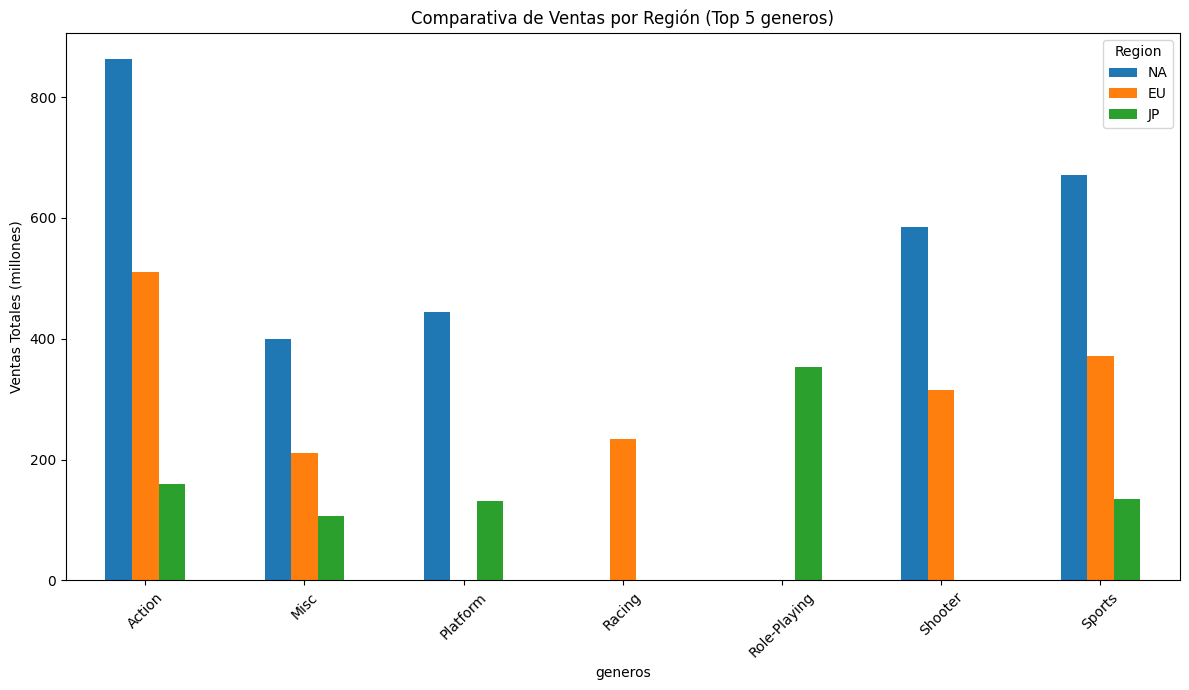

In [22]:
comparativa_generos_region= pd.DataFrame({
	'NA': genres_na_top_5,
	'EU': genres_eu_top_5,
	'JP': genres_jp_top_5

})

comparativa_generos_region.plot(kind='bar', figsize=(12,7))
plt.title('Comparativa de Ventas por Región (Top 5 generos)')
plt.xlabel('generos')
plt.ylabel('Ventas Totales (millones)')
plt.legend(title='Region')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


En Japón, el género RPG (role-playing) es el más popular, mientras que en Europa y Norteamérica no aparece en el top 5. En contraste, el género Shooter, muy fuerte en NA y EU, no figura entre los más vendidos en Japón, mostrando una clara diferencia cultural en preferencias de juego.

El género Action es el único que aparece como el más vendido en los tres mercados, aunque con una gran diferencia de volumen: en NA las ventas de juegos de acción son significativamente mayores que en JP y EU.

Finalmente, Racing aparece como uno de los géneros favoritos en Europa, pero no así en los otros mercados, lo que nuevamente destaca la diversidad regional.

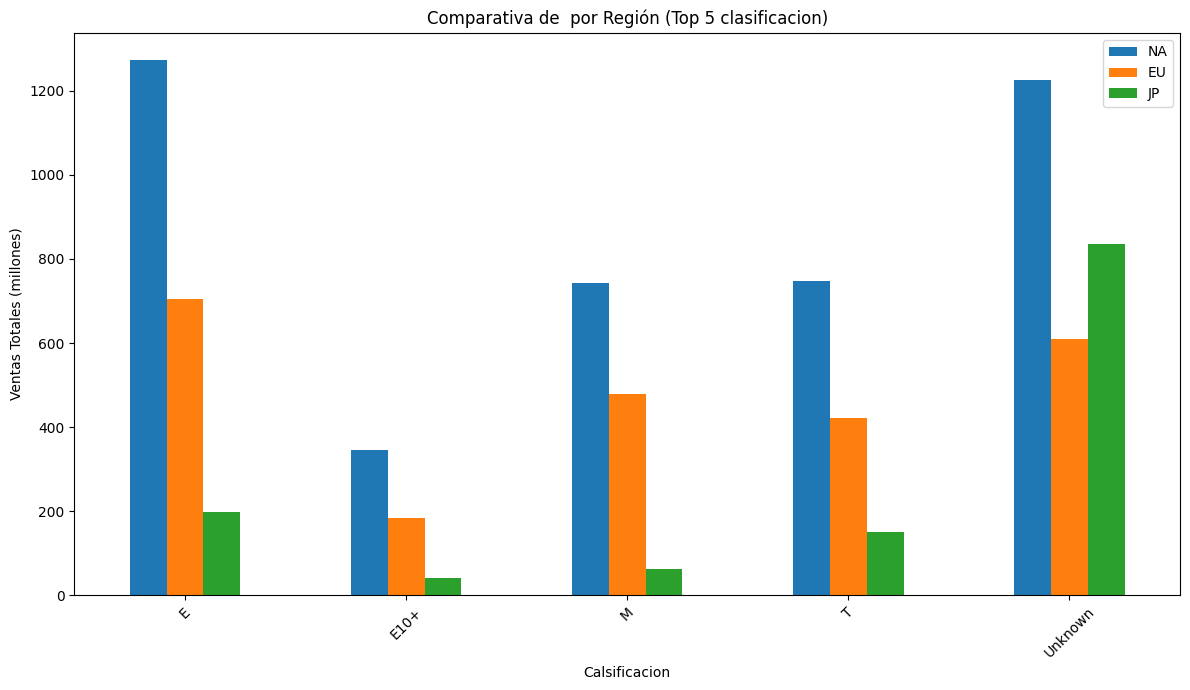

In [23]:
comparativa_rating_region= pd.DataFrame({
	'NA': clasifications_na_top_5,
	'EU' : clasifications_eu_top_5,
	'JP': clasifications_jp_top_5
})

comparativa_rating_region.plot(kind='bar', figsize=(12,7))
plt.title('Comparativa de  por Región (Top 5 clasificacion)')
plt.xlabel('Calsificacion')
plt.ylabel('Ventas Totales (millones)')
plt.legend(title='')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

En cuanto a la clasificación ESRB, en el mercado norteamericano la clasificación E (para todos) es la que acumula mayores ventas, lo cual puede parecer contradictorio si consideramos que los géneros dominantes son Action y Shooter. Sin embargo, esto puede explicarse por bundles o títulos familiares de alto volumen, como juegos de deportes o franquicias como Mario.

Cabe destacar que en este análisis, un porcentaje alto de los datos tienen clasificaciones desconocidas ('Unknown'), lo cual limita un poco la profundidad de este hallazgo. Aproximadamente el 50% de los datos carecen de clasificación ESRB, por lo que estos resultados deben tomarse con cautela.

A lo largo de los distintos gráficos comparativos por región, podemos observar un patrón claro y consistente en las ventas:

Norteamérica (NA) lidera en prácticamente todos los segmentos analizados,
seguida por Europa (EU),
y finalmente Japón (JP), que representa el menor volumen de ventas globales.
Este patrón se repite tanto al analizar plataformas, géneros más populares, como clasificaciones ESRB.
Las diferencias reflejan no solo el tamaño y poder adquisitivo de cada mercado, sino también las preferencias culturales y hábitos de consumo únicos de cada región.

Pruebas de hipotesis.


Hipotesis nula: La calificación promedio de los usuarios para Xbox One y PC es igual.
Hipotesis Alternativa: a calificación promedio de los usuarios para Xbox One y PC es diferente.

In [ ]:
def comparar_medias(sample1, sample2, alpha=0.05):
    resultado = st.ttest_ind(sample1, sample2, nan_policy='omit')  # 'omit' para ignorar NaN por si acaso aunque el df ya esta limpio 
    p_value = resultado.pvalue
    
    print(f'p-value: {p_value:.6f}')
    if p_value < alpha:
        print("Rechazamos la hipótesis nula: las medias son significativamente diferentes.")
    else:
        print("No se puede rechazar la hipótesis nula: no hay evidencia suficiente para decir que las medias difieren.")

juegos_xbox = juegos[juegos['platform'] == 'XOne']['user_score']
juegos_pc = juegos[juegos['platform'] == 'PC']['user_score']

comparar_medias(juegos_xbox, juegos_pc)



p-value: 0.000031
Rechazamos la hipótesis nula: las medias son significativamente diferentes.


Al comprobar esta hipotesis vemos que los usuarios de diferentes plataformas califican de diferente manera, lo que nos puede dar resultados como que un mismo juego tenga diferente calificacion en diferentes plataformas. 

Para efectos de mercado seria mejor analizar cada plataforma por separado.

Hipoteis Nula:Las calificaciones promedio de los usuarios para los géneros Acción y Deportes son iguales.
Hipoteis Alternativa: Las calificaciones promedio de los usuarios para los géneros Acción y Deportes son diferentes.

In [ ]:
#Prueba tstudent de dos variables, con funcion creada en el codigo anterior
calificacion_action= juegos[juegos['genre']=='Action']['user_score']
calificacion_sports= juegos[juegos['genre']=='Sports']['user_score']
comparar_medias(calificacion_action,calificacion_sports)

print(len(calificacion_action))
print(len(calificacion_sports))


p-value: 0.123603
No se puede rechazar la hipótesis nula: no hay evidencia suficiente para decir que las medias difieren.
3307
2306


No hay suficiente evidencia estadística para afirmar que los usuarios califican diferente los juegos de acción y los de deportes. Las medias pueden ser iguales

Para probar las hipótesis se utilizó la prueba de hipótesis para la diferencia de medias (prueba t de Student), ya que el objetivo era comparar si existía una diferencia significativa entre dos grupos independientes:
Por ejemplo: las calificaciones de usuarios para plataformas distintas (Xbox One vs PC), o géneros distintos (Action vs Sports).
Esta prueba es adecuada porque permite determinar si las diferencias observadas en las medias son reales o si pueden atribuirse al azar.
Además, se estableció un nivel de significancia de α = 0.05, que es un estándar común en análisis estadísticos.

El mercado de los videojuegos ha crecido considerablemente en los últimos años. Sin embargo, la verdadera competencia entre plataformas se consolida a partir de la séptima generación, es decir, desde 2005 en adelante. En este periodo se identifican tres claros competidores: Sony, liderando con la PlayStation original y la PS2; Xbox, que logró posicionarse firmemente con la Xbox 360 pero no alcanzó el nivel de la PS4 en este análisis; y Nintendo, destacando por la longevidad de sus consolas y su fuerte presencia en el mercado de consolas portátiles.

También observamos cómo las reseñas, tanto de usuarios como de la crítica profesional, influyen en las ventas de un videojuego, aunque con diferentes grados de correlación.

Las ventas de un mismo videojuego en distintas plataformas pueden variar significativamente debido a los perfiles de consumidores en cada mercado, como vimos con el caso de Need for Speed y el análisis de ventas por géneros y regiones.

Los perfiles demográficos son bastante distintos pero predecibles: en Japón predominan las consolas nacionales y portátiles, mientras que en Europa y Norteamérica la preferencia es por consolas de sobremesa. Asimismo, los géneros más populares varían entre regiones, reflejando diferencias culturales y de consumo.

Un punto importante a considerar es que gran parte de los datos de clasificación ESRB no estaban presentes en el dataset, lo cual puede sesgar los resultados relacionados con ese análisis. En este estudio, se optó por clasificar esos datos como "unknown". Sería recomendable investigar la causa de estas ausencias y mejorar la recolección de datos para futuros análisis, con el fin de entender mejor cómo las clasificaciones afectan el comportamiento del usuario.

Limitaciones e Implicaciones:

Este análisis está limitado por la calidad y disponibilidad de los datos, lo que puede afectar la generalización de algunas conclusiones. Sin embargo, los resultados ofrecen insights valiosos para la industria: los desarrolladores y mercadólogos pueden enfocar sus estrategias considerando las preferencias regionales y los géneros más rentables, así como adaptar sus productos para cada plataforma y perfil de usuario.

Para futuros estudios, sería ideal incluir más variables como datos demográficos de usuarios, precios y campañas de publicidad, así como mejorar la integridad de los datos para reducir sesgos y fortalecer la precisión de los modelos predictivos.